In [6]:
from google.colab import files
uploaded = files.upload("glass+identification.zip")

Saving glass+identification.zip to glass+identification.zip/glass+identification (2).zip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

with zipfile.ZipFile('glass+identification.zip', 'r') as zip_ref:
    zip_ref.extractall('glass_data')

print("Files extracted successfully!")

Files extracted successfully!


In [ ]:
import pandas as pd
columns = [
    'ID', 'RI', 'Na', 'Mg', 'Al',
    'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'
]
df = pd.read_csv(
    'glass_data/glass.data',
    header=None,
    names=columns
)

In [ ]:
df.to_csv('glass_identification.csv', index=False)

print("CSV file created successfully!")

CSV file created successfully!


In [ ]:
df.isnull().sum()

,0
ID,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0


In [ ]:
df.shape

(214, 11)

In [ ]:
df.describe()

,ID,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,107.500000,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,61.920648,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.000000,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,54.250000,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,107.500000,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,160.750000,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,214.000000,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [ ]:
df['Type'].value_counts()

,count
Type,
2,76
1,70
7,29
3,17
5,13
6,9


In [ ]:
df.columns


Index(['ID', 'RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='object')

In [ ]:
df.groupby('Type')[['RI', 'Na', 'Mg', 'Al']].mean()

,RI,Na,Mg,Al
Type,,,,
1,1.518718,13.242286,3.552429,1.163857
2,1.518619,13.111711,3.002105,1.408158
3,1.517964,13.437059,3.543529,1.201176
5,1.518928,12.827692,0.773846,2.033846
6,1.517456,14.646667,1.305556,1.366667
7,1.517116,14.442069,0.538276,2.122759


In [ ]:
Mean_val=df.groupby('Type')[['Mg']].max()
print(Mean_val.max())

Mg    4.49
dtype: float64


In [ ]:
df.sort_values(by='Na',ascending=True).head(10)

,ID,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
106,107,1.53125,10.73,0.00,2.10,69.81,0.58,13.30,3.15,0.28,2
111,112,1.52739,11.02,0.00,0.75,73.08,0.00,14.96,0.00,0.00,2
166,167,1.52151,11.03,1.71,1.56,73.44,0.58,11.62,0.00,0.00,5
110,111,1.52664,11.23,0.00,0.77,73.21,0.00,14.68,0.00,0.00,2
105,106,1.52475,11.45,0.00,1.88,72.19,0.81,13.24,0.00,0.34,2
165,166,1.52171,11.56,1.88,1.56,72.86,0.47,11.41,0.00,0.00,5
201,202,1.51653,11.95,0.00,1.19,75.18,2.70,8.93,0.00,0.00,7
149,150,1.51643,12.16,3.52,1.35,72.89,0.57,8.53,0.00,0.00,3
97,98,1.51743,12.20,3.25,1.16,73.55,0.62,8.90,0.00,0.24,2
107,108,1.53393,12.30,0.00,1.00,70.16,0.12,16.19,0.00,0.24,2


In [ ]:
df.isnull().sum()

,0
ID,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
Average_val=df.groupby('Type').mean()
# Compare average chemical values between glass types

avg_values = df.groupby('Type')[['Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']].mean()

print("Average Chemical Values Across Glass Types:")
print(avg_values)

# Find the highest and lowest averages for each chemical component

print("\nGlass type with the highest average:")
print(avg_values.idxmax())

print("\nHighest average values:")
print(avg_values.max())

print("\nGlass type with the lowest average:")
print(avg_values.idxmin())

print("\nLowest average values:")
print(avg_values.min())

Average Chemical Values Across Glass Types:
             Na        Mg        Al         Si         K         Ca        Ba  \
Type                                                                            
1     13.242286  3.552429  1.163857  72.619143  0.447429   8.797286  0.012714   
2     13.111711  3.002105  1.408158  72.598026  0.521053   9.073684  0.050263   
3     13.437059  3.543529  1.201176  72.404706  0.406471   8.782941  0.008824   
5     12.827692  0.773846  2.033846  72.366154  1.470000  10.123846  0.187692   
6     14.646667  1.305556  1.366667  73.206667  0.000000   9.356667  0.000000   
7     14.442069  0.538276  2.122759  72.965862  0.325172   8.491379  1.040000   

            Fe  
Type            
1     0.057000  
2     0.079737  
3     0.057059  
5     0.060769  
6     0.000000  
7     0.013448  

Glass type with the highest average:
Na    6
Mg    1
Al    7
Si    6
K     5
Ca    5
Ba    7
Fe    2
dtype: int64

Highest average values:
Na    14.646667
Mg     3.552429

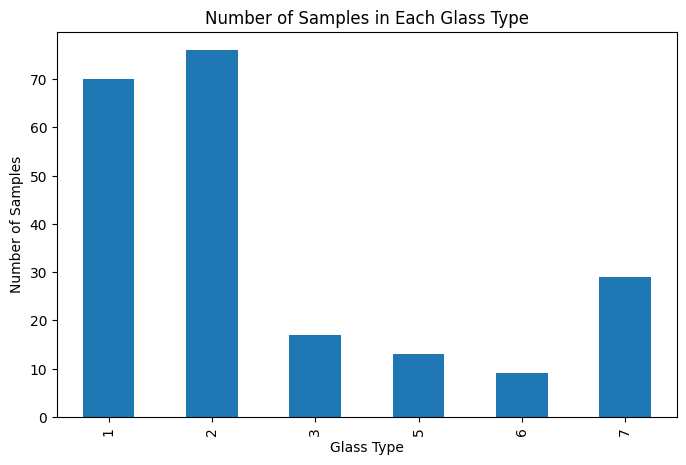

In [ ]:
import matplotlib.pyplot as plt

glass_counts = df['Type'].value_counts().sort_index()

glass_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Number of Samples in Each Glass Type')
plt.xlabel('Glass Type')
plt.ylabel('Number of Samples')
plt.show()

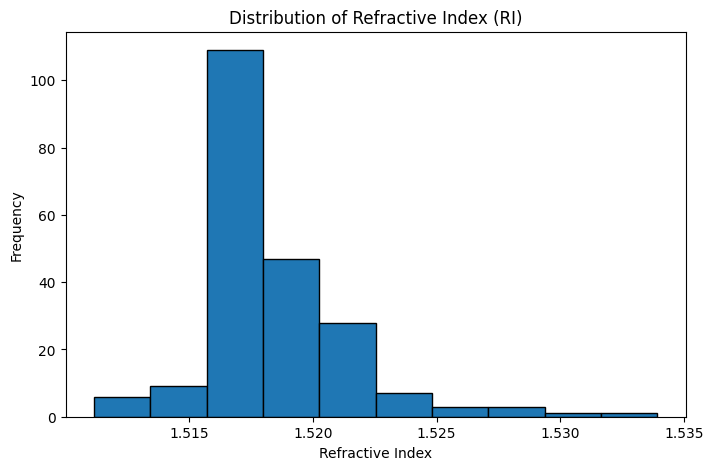

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df['RI'], bins=10, edgecolor='black')

plt.title('Distribution of Refractive Index (RI)')
plt.xlabel('Refractive Index')
plt.ylabel('Frequency')

plt.show()

In [ ]:
''' #observations
1. Glass Type 2 has the highest number of samples (76), while Glass Type 6 has the lowest number of samples (9).
2. The dataset contains 214 samples and 11 columns, and no missing values were found in any column.
3. No duplicate rows were found in the dataset, which means all 214 rows are unique.'''

' #observations\n1. Glass Type 2 has the highest number of samples (76), while Glass Type 6 has the lowest number of samples (9).\n2. The dataset contains 214 samples and 11 columns, and no missing values were found in any column.\n3. No duplicate rows were found in the dataset, which means all 214 rows are unique.'

In [ ]:
import numpy as np

na_array = np.array(df['Na'])

print("Average Sodium:", np.mean(na_array))
print("Maximum Sodium:", np.max(na_array))
print("Minimum Sodium:", np.min(na_array))

Average Sodium: 13.407850467289718
Maximum Sodium: 17.38
Minimum Sodium: 10.73
